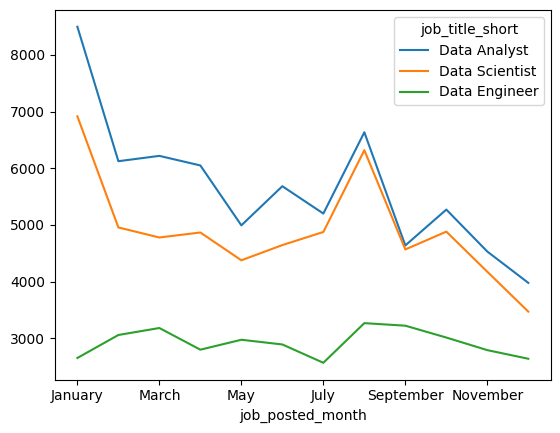

In [11]:
import ast
import pandas as pd
from datasets import load_dataset
import matplotlib.pyplot as plt

dataset = load_dataset('lukebarousse/data_jobs')
df = dataset['train'].to_pandas()
df['job_posted_date'] = pd.to_datetime(df['job_posted_date'])

df_US = df[df['job_country'] == 'United States'].copy()
df_US['job_posted_month'] = df_US['job_posted_date'].dt.strftime('%B')

df_US_pivot = df_US.pivot_table(index='job_posted_month', columns='job_title_short', aggfunc='size')
df_US_pivot.reset_index(inplace=True)

# Tri chronologique des mois
df_US_pivot['month_no'] = pd.to_datetime(df_US_pivot['job_posted_month'], format='%B').dt.month
df_US_pivot = df_US_pivot.sort_values('month_no')
df_US_pivot.drop(columns='month_no', inplace=True)

# Sélectionner le top 3 des métiers
top_3 = df_US['job_title_short'].value_counts().head(3).index.tolist()

# Tracer le graphique pour le top 3
df_US_pivot.set_index('job_posted_month')[top_3].plot(kind='line')
plt.show()